# Supplementary figure — Regional cultural shares

**Purpose:** Generate one figure from user-supplied inputs.

**Required inputs:** City-state CSV with CityID, time and N/H/I/A/R cultural-state columns, plus a city POINT shapefile with CityID/CDT_type.

**Dependencies:** numpy, pandas, matplotlib, pyshp; openpyxl for Excel input. Install these in your Python environment.

**Data availability:** Input records and private local paths are not included. The final figure is embedded as a PNG output for inspection. Configure the paths below, then run all cells.

**Display conventions:** S01 is a provisional supplementary identifier, not a confirmed manuscript figure number. Historical weights are N/H=1, I=0.7, A=0.5, R=0; per-city counts are truncated before normalization. The plot uses the latest available time within 1..41.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
# Set these directories to your own input location and a writable output location.
DATA_DIR = Path("input_data")
OUTPUT_DIR = Path("figure_output")
plt.rcParams["font.family"] = "Arial"
config = {'inputs': {'state': 'city_states.csv', 'cities': 'city_points.shp'}, 'start_time': 1, 'end_time': 20, 'positive_growth_divisors': {'G': 3}, 'culture_fit_degree': 5, 'pooled_fit_degree': 4, 'appendix_weights': {'N': 1, 'H': 1, 'I': 0.7, 'A': 0.5, 'R': 0}, 'appendix_truncate': True, 'appendix_bar_culture': 'G', 'national_culture': 'C', 'national_jitter_amplitude': 2e-05, 'random_seed': 20261011, 'output_dir': 'figure_output', 'dpi': 300}
config["inputs"] = {key: str((DATA_DIR / value).resolve()) for key, value in config["inputs"].items()}
config["output_dir"] = str(OUTPUT_DIR.resolve())


## Self-contained data loading and plotting helpers
No sibling Python module is required.

In [ ]:
"""Snapshot parser and cultural-label counts (dual labels counted in both cultures)."""
import csv
from pathlib import Path
import pandas as pd

IDENTIFIERS = frozenset({'N', 'H', 'R', '0', 'I', 'A'})


def culture_labels(columns):
    """Stable order and exact token matching."""
    return list(dict.fromkeys(token for column in columns for token in column.split('_')
                             if token not in IDENTIFIERS))


def read_csv(filepath):
    """Initial header, then blank-separated snapshots; repeated headers optional.

    Preserve the first city of every block and flush the final block at EOF.
    """
    snapshots, block, header = [], [], None

    def flush():
        if not block:
            return
        frame = pd.DataFrame(block, columns=header).set_index(header[0])
        if frame.index.has_duplicates:
            raise ValueError('Duplicate CityID in a snapshot')
        snapshots.append(frame.apply(pd.to_numeric, errors='raise'))
        block.clear()

    with Path(filepath).open(encoding='utf-8-sig', newline='') as source:
        for line, row in enumerate(csv.reader(source), 1):
            if not row or all(not item.strip() for item in row):
                flush()
            elif header is None:
                header = row
                if len(set(header)) != len(header):
                    raise ValueError('Duplicate CSV columns')
            elif row == header:
                flush()
            else:
                if len(row) != len(header):
                    raise ValueError(f'Line {line}: expected {len(header)} columns, got {len(row)}')
                block.append(row)
        flush()
    if not snapshots:
        raise ValueError('CSV contains no snapshots')
    return snapshots


def compute_culture(df, coverage='all'):
    totals = df.apply(pd.to_numeric, errors='raise').sum(axis=0)
    counts = {label: totals[[label in col.split('_') for col in df.columns]].sum().item()
              for label in culture_labels(df.columns)}
    if coverage == 'all':
        return counts
    if coverage == 'region':
        denominator = sum(counts.values())
        if denominator == 0:
            raise ValueError('Total cultural label count is zero')
        return {label: count / denominator for label, count in counts.items()}
    raise ValueError("coverage must be 'all' or 'region'")


def compulte_culture(df, coverage='all'):
    """Backward-compatible alias for existing imports."""
    return compute_culture(df, coverage)


def culture_series(snapshots):
    counts = pd.DataFrame([compute_culture(frame) for frame in snapshots])
    denominator = counts.sum(axis=1)
    if denominator.eq(0).any():
        raise ValueError('A snapshot has zero total cultural label count')
    return counts, counts.div(denominator, axis=0)

"""Explicit data preparation and shared styles for the three notebooks."""
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import shapefile


CULTURES = ('J', 'L', 'G', 'B', 'E', 'X', 'F', 'D', 'C', 'K', 'M')
COLORS = dict(zip(CULTURES, ('#a888c1', '#8daec2', '#96d294', '#ceb69a',
                           '#a4cec8', '#c6b1d0', '#9ba3d6', '#e29690',
                           '#c9d195', '#cd90b7', '#c8929b')))
NAMES = dict(zip(CULTURES, ('Sichuan and Chongqing Culture', 'Jiangnan Culture',
                          'Yunnan-Guizhou Culture', 'Inner Mongolia Culture',
                          'North China Culture', 'Northeastern Culture',
                          'Tibetan Culture', 'Loess Plateau Culture',
                          'Xinjiang Culture', 'Jingchu Culture', 'South China Culture')))
# Historical manually assigned guide lines, not fitted classifications.
GUIDES_KM = dict.fromkeys(('J', 'L', 'E', 'D', 'K', 'M'), 500)
GUIDES_KM.update(dict.fromkeys(('G', 'C', 'F'), 1000))


def load_config():
    return config


def input_path(config, key):
    path = (ROOT / config['inputs'][key]).resolve()
    if not path.is_file():
        raise FileNotFoundError(f'{key}: {path}. Update inputs in {ROOT / "config.json"}')
    return path


def read_points(path, key, encoding='gbk', duplicate_policy='last'):
    """Read POINT shapefile without geopandas; coordinates remain unchanged."""
    with shapefile.Reader(str(path), encoding=encoding) as reader:
        fields = list(dict.fromkeys((key, 'CDT_type')))
        records = [record.as_dict() for record in reader.records(fields=fields)]
        geometry = reader.shapes()
        if any(shape.shapeType != shapefile.POINT for shape in geometry):
            raise ValueError('Only POINT shapefiles are supported')
        frame = pd.DataFrame(records)
        frame[['x', 'y']] = [shape.points[0] for shape in geometry]
    duplicates = frame.loc[frame[key].duplicated(keep=False), key].unique()
    if len(duplicates):
        if duplicate_policy != 'last':
            raise ValueError(f'Duplicate {key}: {duplicates.tolist()} in {path}')
        warnings.warn(f'Duplicate {key} {duplicates.tolist()}; retain last record as in historical dictionaries')
        frame = frame.drop_duplicates(key, keep='last')
    return frame.set_index(key)


def growth_rates(proportions, start_time=1, end_time=20):
    """Match endpoints by CityID instead of CSV row position."""
    if proportions.duplicated(['CityID', 'time']).any():
        raise ValueError('Duplicate CityID/time observations')
    first, last = [proportions.loc[proportions.time.eq(t)].set_index('CityID')
                   for t in (start_time, end_time)]
    if first.empty or last.empty or set(first.index) != set(last.index):
        raise ValueError('Endpoints must contain the same nonempty set of CityIDs')
    if any(c not in first.columns for c in CULTURES):
        raise ValueError('Missing cultural proportion columns')
    initial = first.loc[:, CULTURES]
    if initial.eq(0).any().any():
        raise ValueError('Growth rate is undefined for an initial proportion of zero')
    result = (last.loc[first.index, CULTURES] - initial) / initial
    if not np.isfinite(result.to_numpy()).all():
        raise ValueError('Growth rates contain nonfinite values')
    return result


def distance_growth(growth, cities, centers, positive_divisors=None):
    """Euclidean distance in km, with explicit optional display scaling.

    Scaling affects plot data only, never raw growth. The bundled shapefiles
    share CGCS2000 Lambert coordinates in metres.
    """
    city_ids = cities.index.intersection(growth.index, sort=False)
    missing = growth.index.difference(cities.index)
    if len(missing):
        warnings.warn(f'{len(missing)} cities lack coordinates and are excluded: {missing.tolist()}')
    if not len(city_ids):
        raise ValueError('No shared CityID between growth and coordinates')
    points = cities.loc[city_ids, ['x', 'y']].to_numpy(dtype=float)
    centers = centers.copy()
    centers.index = centers.index.astype(str).str[0]
    if centers.index.has_duplicates:
        raise ValueError('Duplicate culture centers')
    result = {}
    for culture in CULTURES:
        values = growth.loc[city_ids, culture].to_numpy(copy=True)
        divisor = (positive_divisors or {}).get(culture, 1)
        if not np.isfinite(divisor) or divisor <= 0:
            raise ValueError('Positive-growth divisors must be finite and > 0')
        if divisor != 1:
            warnings.warn(f'Historical display transform: positive {culture} growth / {divisor}')
            values[values > 0] /= divisor
        center = centers.loc[culture, ['x', 'y']].to_numpy(dtype=float)
        distance = np.linalg.norm(points - center, axis=1) / 1000
        result[culture] = pd.DataFrame({'distance_km': distance, 'growth': values}, index=city_ids)
    return result


def regional_shares(state, cities, weights, truncate=True):
    """Historical weighted-label shares, with optional per-city truncation.

    Preserve original addition order before truncating to avoid round-off
    changing integer counts. Negative source counts are not clipped.
    """
    if state.duplicated(['CityID', 'time']).any():
        raise ValueError('Duplicate CityID/time observations')
    genes = [c for c in state.columns if '_' in c]
    if set(culture_labels(genes)) != set(CULTURES):
        raise ValueError('Unexpected cultures in state columns')
    counts = np.zeros((len(state), len(CULTURES)), dtype=float)
    for gene in genes:
        status, *labels = gene.split('_')
        if status not in weights:
            raise ValueError(f'Missing weight for status {status}')
        values = state[gene].to_numpy(dtype=float) * weights[status]
        for i, culture in enumerate(CULTURES):
            if culture in labels:
                counts[:, i] += values
    if truncate:
        counts = np.trunc(counts)
    frame = pd.DataFrame(counts, columns=CULTURES)
    frame['time'] = state['time'].to_numpy()
    frame['region'] = state['CityID'].map(cities['CDT_type']).to_numpy()
    missing = state.loc[frame.region.isna().to_numpy(), 'CityID'].unique()
    if len(missing):
        warnings.warn(f'{len(missing)} cities lack region labels and are excluded: {missing.tolist()}')
    frame = frame.dropna(subset=['region'])
    city_totals = frame.loc[:, CULTURES].sum(axis=1)
    if city_totals.eq(0).any():
        raise ValueError('A city has zero total weighted cultural counts')
    totals = frame.groupby(['time', 'region'])[list(CULTURES)].sum()
    denominator = totals.sum(axis=1)
    if denominator.eq(0).any():
        raise ValueError('A region has zero total weighted cultural counts')
    shares = totals.div(denominator, axis=0)
    individual = frame.loc[:, CULTURES].div(city_totals, axis=0)
    groups = [frame['time'], frame['region']]
    return shares, individual.groupby(groups).min(), individual.groupby(groups).max()


def style_axis(ax, xlabel, ylabel):
    for name in ('bottom', 'left'):
        ax.spines[name].set(linewidth=0.5, color='gray')
    for name in ('top', 'right'):
        ax.spines[name].set_visible(False)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.tick_params(axis='both', labelsize=10)


def fitted_curve(ax, data, degree, color, alpha=0.75):
    """Retain historical degree and low-end truncation for comparison."""
    data = data.sort_values('distance_km')
    x, y = data['distance_km'].to_numpy(), data['growth'].to_numpy()
    if not np.isfinite(np.c_[x, y]).all() or len(np.unique(x)) <= degree:
        raise ValueError('Insufficient distinct finite distances for polynomial fit')
    fit = np.poly1d(np.polyfit(x, y, degree))
    fitted = fit(x)
    valid = np.flatnonzero(fitted >= y.min())
    start = int(valid[0]) if len(valid) else 0
    ax.plot(x[start:], fitted[start:], color=color, linewidth=4,
            alpha=alpha, linestyle='--')


def save_figure(fig, name, config):
    directory = (ROOT / config['output_dir']).resolve()
    directory.mkdir(parents=True, exist_ok=True)
    for extension in ('png', 'pdf'):
        fig.savefig(directory / f'{name}.{extension}', dpi=config['dpi'], bbox_inches='tight')
    return directory


## Generate the figure
PNG/PDF outputs are written to OUTPUT_DIR. Existing files with the same names are overwritten.

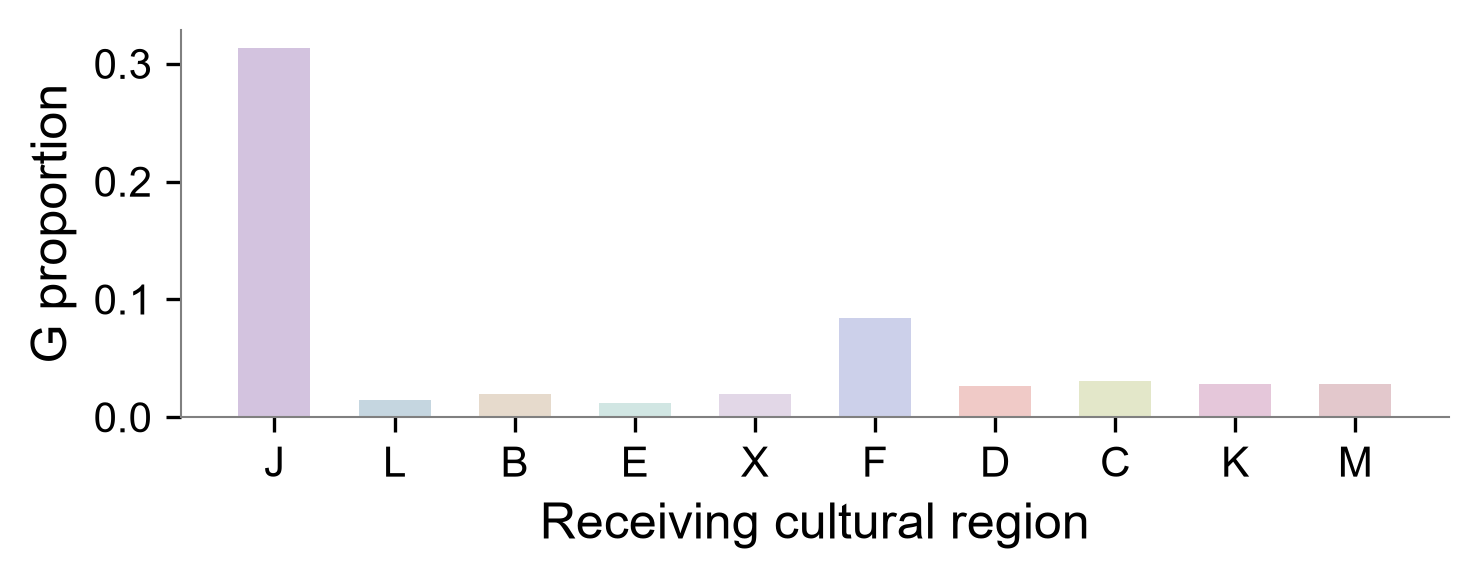

In [ ]:
cities = read_points(input_path(config, 'cities'), 'CityID')
state = pd.read_csv(input_path(config, 'state'))
regional, regional_min, regional_max = regional_shares(state, cities, config['appendix_weights'], config['appendix_truncate'])
regional = regional.loc[regional.index.get_level_values('time').isin(range(1, 42))]
culture = config['appendix_bar_culture']
regions = [c for c in CULTURES if c != culture]
last_time = regional.index.get_level_values('time').max()
values = regional.loc[(last_time, regions), culture]
fig, ax = plt.subplots(figsize=(5, 2), dpi=config['dpi'])
ax.bar(np.arange(len(regions)), values, color=[COLORS[c] for c in regions], width=0.6, alpha=0.5)
ax.set_xticks(np.arange(len(regions)), regions)
style_axis(ax, 'Receiving cultural region', f'{culture} proportion')
fig.tight_layout()
save_figure(fig, 'appendix_regional_share', config)
plt.close('all')
